# Extracción macroeconómica del Perú: 2005–2025

Series oficiales de [BCRPData](https://estadisticas.bcrp.gob.pe/estadisticas/series/ayuda/api), originales verificables y consolidación anual. Los datos son revisados a la fecha de consulta, no versiones históricas disponibles en tiempo real.

**1. Entorno y rutas del proyecto**

Se preparan las bibliotecas y las carpetas del proyecto. Se registran versiones y hashes de los archivos preexistentes para comprobar su conservación.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata as metadata
import json
import platform
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "README.md").is_file() and (ROOT / "notebooks").is_dir()
RAW = ROOT / "data/raw/bcrp"
PROCESSED = ROOT / "data/processed"
RAW.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)
REPORTS = ROOT / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)
CORTE_RIQ = 2021
protegidos = [ROOT / "README.md", ROOT / "notebooks/EDA_FCL_2005_2025.ipynb",
              ROOT / "notebooks/02_feature_engineering.ipynb"]
hashes_iniciales = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in protegidos}
etapas = []
ANIOS = pd.Index(range(2005, 2026), name="anio")
ACTUALIZAR = False  # True vuelve a consultar; False reutiliza originales con SHA-256 verificado.
BASE = "https://estadisticas.bcrp.gob.pe/estadisticas/series"
plt.rcParams.update({"figure.figsize": (11, 6), "axes.grid": True, "grid.alpha": 0.25})
versiones = {p: metadata.version(p) for p in ["pandas", "numpy", "matplotlib", "requests", "nbformat", "nbclient"]}
print("Python:", platform.python_version())
display(pd.Series(versiones, name="version").to_frame())
etapas.append(1)

Python: 3.12.15


,version
pandas,3.0.6
numpy,2.5.4
matplotlib,3.11.2
requests,2.34.2
nbformat,5.11.1
nbclient,0.11.0


El entorno y sus versiones quedan registrados. Los hashes iniciales permiten verificar al final que el README y los notebooks anteriores se conservan.

**2. Fuentes y criterios de anualización**

Se identifican las cinco series oficiales y sus unidades. El PBI conserva su nivel y crecimiento anual; la inflación mide diciembre/diciembre y cambio y tasa usan la media de 12 meses, con igual peso mensual.
La inflación de cierre difiere de la variación de IPC medios anuales; el cambio mensual de diciembre tampoco representa la cotización del último día. Se conserva cada definición sin imponerles una misma agregación.

In [2]:
series = pd.DataFrame([
    {"codigo": "PM04860AA", "variable": "pbi_real_millones_soles_2007", "descripcion": "PBI real, millones de soles de 2007", "frecuencia": "A", "inicio": "2005", "fin": "2025", "unidad_final": "Millones S/ de 2007", "metodo": "Valor anual original", "fuente_original": "INEI, BCRP"},
    {"codigo": "PN38705PM", "variable": "inflacion_lima_dic_dic_pct", "descripcion": "IPC Lima Metropolitana, diciembre 2021 = 100", "frecuencia": "M", "inicio": "2004-12", "fin": "2025-12", "unidad_final": "% diciembre/diciembre", "metodo": "100 * (IPC diciembre / IPC diciembre previo - 1)", "fuente_original": "INEI"},
    {"codigo": "PN01206PM", "variable": "tipo_cambio_promedio_soles_usd", "descripcion": "Tipo de cambio interbancario venta, promedio mensual", "frecuencia": "M", "inicio": "2005-1", "fin": "2025-12", "unidad_final": "S/ por US$", "metodo": "Media aritmetica de 12 observaciones mensuales", "fuente_original": "BCRP, SBS, Reuters, Datatec"},
    {"codigo": "PD04722MM", "variable": "tasa_referencia_promedio_pct", "descripcion": "Tasa de referencia de la politica monetaria", "frecuencia": "M", "inicio": "2005-1", "fin": "2025-12", "unidad_final": "%", "metodo": "Media aritmetica de 12 observaciones mensuales", "fuente_original": "BCRP"},
])
series.loc[len(series)] = {"codigo": "PM04863AA", "variable": "crecimiento_pbi_real_pct",
    "descripcion": "Variacion porcentual anual del PBI real", "frecuencia": "A", "inicio": "2005", "fin": "2025",
    "unidad_final": "%", "metodo": "Variacion anual oficial del BCRP; no se infiere estacionariedad",
    "fuente_original": "INEI, BCRP"}
series["disponibilidad"] = ("Dato revisado consultado, no vintage historico. Publicado despues del periodo de referencia; "
    "verificar fecha efectiva de publicacion antes de pronosticar. Union futura solo anio = Ejercicio (t), "
    "nunca anio_objetivo (t+1); esta llave sola no evita fuga por revisiones o rezagos de publicacion.")
series["ponderacion"] = np.where(series.frecuencia.eq("M"), "Media de registros mensuales: igual peso 1/12 cuando aplica; no media diaria", "No aplica")
series["alcance"] = ["Peru", "Lima Metropolitana", "Interbancario venta", "Politica monetaria", "Peru"]
series["url_api"] = series.apply(lambda s: f"{BASE}/api/{s.codigo}/json/{s.inicio}/{s.fin}/esp", axis=1)
series["url_ficha"] = series.apply(lambda s: f"{BASE}/{'anuales' if s.frecuencia == 'A' else 'mensuales'}/resultados/{s.codigo}/html", axis=1)
display(series[["codigo", "descripcion", "frecuencia", "unidad_final", "metodo"]])
etapas.append(2)

,codigo,descripcion,frecuencia,unidad_final,metodo
0,PM04860AA,"PBI real, millones de soles de 2007",A,Millones S/ de 2007,Valor anual original
1,PN38705PM,"IPC Lima Metropolitana, diciembre 2021 = 100",M,% diciembre/diciembre,100 * (IPC diciembre / IPC diciembre previo - 1)
2,PN01206PM,"Tipo de cambio interbancario venta, promedio m...",M,S/ por US$,Media aritmetica de 12 observaciones mensuales
3,PD04722MM,Tasa de referencia de la politica monetaria,M,%,Media aritmetica de 12 observaciones mensuales
4,PM04863AA,Variacion porcentual anual del PBI real,A,%,Variacion anual oficial del BCRP; no se infier...


Las cinco series distinguen nivel y crecimiento del PBI, IPC de Lima, dólar interbancario y tasa monetaria. Sus definiciones y restricciones temporales quedan en el diccionario.

**3. Consulta de la API y conservación de originales**

Se consultan las series con timeout, reintentos y errores identificados por código y URL. La caché verifica hashes sin escribir en raw; las actualizaciones conservan las versiones anteriores.

In [3]:
session = requests.Session()
session.mount("https://", HTTPAdapter(max_retries=Retry(
    total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504], allowed_methods=["GET"])))
manifest_path = RAW / "manifest_2005_2025.json"
anterior = json.loads(manifest_path.read_text(encoding="utf-8")) if manifest_path.exists() else {}
respuestas, manifiesto, resumen, pendientes = {}, {}, [], []
try:
    for s in series.itertuples(index=False):
        archivo = RAW / f"{s.codigo}_{s.inicio}_{s.fin}.json"
        previo = anterior.get(s.codigo)
        if archivo.exists() and previo and not ACTUALIZAR:
            contenido = archivo.read_bytes()
            if hashlib.sha256(contenido).hexdigest() != previo["sha256"] or previo["url"] != s.url_api:
                raise ValueError(f"Cache alterada o URL incompatible: {s.codigo}")
            info, origen = previo, "cache verificada"
        else:
            try:
                r = session.get(s.url_api, timeout=(10, 60))
                r.raise_for_status()
                tipo = r.headers.get("Content-Type", "").lower()
                # BCRP puede servir JSON valido con Content-Type text/html; validar el cuerpo.
                contenido = r.content
            except (requests.exceptions.RequestException, ValueError) as exc:
                raise RuntimeError(f"Fallo HTTP para {s.codigo}: {s.url_api}; {exc}") from exc
            info = {"url": r.url, "consultado_utc": datetime.now(timezone.utc).isoformat(),
                    "archivo": str(archivo.relative_to(ROOT)), "sha256": hashlib.sha256(contenido).hexdigest(),
                    "http_status": r.status_code, "content_type": tipo}
            origen = "API BCRP"
        try:
            payload = json.loads(contenido)
            if not isinstance(payload, dict) or not isinstance(payload["periods"], list) or not payload["periods"]:
                raise ValueError("Sin periodos validos")
            if len(payload["config"]["series"]) != 1 or not payload["config"]["series"][0]["name"]:
                raise ValueError("Metadatos de serie incompletos")
            if not all(isinstance(p["name"], str) and isinstance(p["values"], list) and len(p["values"]) == 1 for p in payload["periods"]):
                raise ValueError("Estructura de periodos inesperada")
        except (json.JSONDecodeError, UnicodeDecodeError, KeyError, TypeError, ValueError, IndexError) as exc:
            raise RuntimeError(f"Respuesta invalida para {s.codigo}: {s.url_api}; {exc}") from exc
        if origen == "API BCRP":
            pendientes.append((archivo, contenido))
        respuestas[s.codigo] = payload
        manifiesto[s.codigo] = info
        resumen.append({"codigo": s.codigo, "registros": len(payload["periods"]), "origen": origen,
                        "nombre_api": payload["config"]["series"][0]["name"]})
finally:
    session.close()
if pendientes:
    # Conservar cada version anterior antes de actualizar; la cache pura no escribe en raw.
    if manifest_path.exists():
        digest = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
        archivo_manifest = RAW / "versiones" / f"manifest_{digest}.json"
        archivo_manifest.parent.mkdir(exist_ok=True)
        if not archivo_manifest.exists():
            archivo_manifest.write_bytes(manifest_path.read_bytes())
    for archivo, contenido in pendientes:
        if archivo.exists() and archivo.read_bytes() != contenido:
            digest = hashlib.sha256(archivo.read_bytes()).hexdigest()
            respaldo = RAW / "versiones" / f"{archivo.stem}_{digest}.json"
            respaldo.parent.mkdir(exist_ok=True)
            if not respaldo.exists():
                respaldo.write_bytes(archivo.read_bytes())
        temporal = archivo.with_suffix(".tmp")
        temporal.write_bytes(contenido)
        temporal.replace(archivo)
    temporal = manifest_path.with_suffix(".tmp")
    temporal.write_text(json.dumps(manifiesto, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    temporal.replace(manifest_path)
display(pd.DataFrame(resumen))
etapas.append(3)

,codigo,registros,origen,nombre_api
0,PM04860AA,21,cache verificada,Producto bruto interno y otros indicadores - P...
1,PN38705PM,253,cache verificada,Índice de precios Lima Metropolitana (índice D...
2,PN01206PM,252,cache verificada,Tipo de cambio - promedio del periodo (S/ por ...
3,PD04722MM,252,cache verificada,Tasas de interés del Banco Central de Reserva ...
4,PM04863AA,21,cache verificada,Producto bruto interno y otros indicadores - P...


Las respuestas incluyen los nombres oficiales y sus registros. Diciembre de 2004 se usa solo como base del cálculo de inflación de 2005.

**4. Conversión de periodos y valores numéricos**

Se interpretan los periodos anuales y las abreviaturas mensuales, incluidas sep/set/sept. Los faltantes se conservan como NaN; los formatos numéricos inesperados detienen la ejecución.

In [4]:
MESES = {m: i for i, m in enumerate(["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"], 1)}
MESES.update({"set": 9, "sept": 9})
def fecha_bcrp(texto, frecuencia):
    texto = str(texto).strip()
    if frecuencia == "A":
        assert re.fullmatch(r"\d{4}", texto), texto
        return pd.Timestamp(int(texto), 1, 1)
    match = re.fullmatch(r"([A-Za-z]+)\.?(\d{4})", texto)
    assert match and match[1].lower() in MESES, texto
    return pd.Timestamp(int(match[2]), MESES[match[1].lower()], 1)

tablas = {}
for s in series.itertuples(index=False):
    periodos = respuestas[s.codigo]["periods"]
    t = pd.DataFrame({"periodo_original": [p["name"] for p in periodos],
                      "valor_original": [p["values"][0] for p in periodos]})
    t["fecha"] = t.periodo_original.map(lambda p: fecha_bcrp(p, s.frecuencia))
    texto = t.valor_original.astype("string").str.strip()
    ausentes = texto.isna() | texto.str.lower().isin(["", "n.d.", "n.d", "nd", "na", "n/a", "nan", "null", "s.d."])
    t["valor"] = pd.to_numeric(texto.mask(ausentes), errors="raise").astype(float)
    assert np.isfinite(t.loc[t.valor.notna(), "valor"]).all(), s.codigo
    t["codigo"] = s.codigo
    tablas[s.codigo] = t.sort_values("fecha").reset_index(drop=True)
display(pd.concat([t.head(2) for t in tablas.values()], ignore_index=True))
etapas.append(4)

,periodo_original,valor_original,fecha,valor,codigo
0,2005,273971.153886791,2005-01-01,273971.153887,PM04860AA
1,2006,294597.830810429,2006-01-01,294597.830810,PM04860AA
2,Dic.2004,60.9430396954876,2004-12-01,60.943040,PN38705PM
3,Ene.2005,61.0040738479291,2005-01-01,61.004074,PN38705PM
4,Ene.2005,3.27088095238095,2005-01-01,3.270881,PN01206PM
5,Feb.2005,3.2598,2005-02-01,3.259800,PN01206PM
6,Ene.2005,3,2005-01-01,3.000000,PD04722MM
7,Feb.2005,3,2005-02-01,3.000000,PD04722MM
8,2005,6.28520816596756,2005-01-01,6.285208,PM04863AA
9,2006,7.52877689165798,2006-01-01,7.528777,PM04863AA


Los registros quedan ordenados por fecha con valores numéricos. Los originales y sus etiquetas se conservan para rastrear cada observación.

**5. Calidad y cobertura de los originales**

Se contrastan los periodos con el calendario y se cuentan faltantes, duplicados y registros fuera de rango. La anualización exige cobertura completa y no imputa observaciones.

In [5]:
controles = []
for s in series.itertuples(index=False):
    t = tablas[s.codigo]
    esperado = pd.date_range(f"{s.inicio}-01" if s.frecuencia == "M" else f"{s.inicio}-01-01",
                            f"{s.fin}-01" if s.frecuencia == "M" else f"{s.fin}-01-01",
                            freq="MS" if s.frecuencia == "M" else "YS")
    recibidos = pd.DatetimeIndex(t.fecha)
    controles.append({"codigo": s.codigo, "esperados": len(esperado), "recibidos": len(t),
        "periodos_ausentes": len(esperado.difference(recibidos)),
        "fuera_rango": len(recibidos.difference(esperado)),
        "duplicados": int(t.duplicated("fecha").sum()), "valores_faltantes": int(t.valor.isna().sum())})
calidad = pd.DataFrame(controles)
display(calidad)
assert calidad[["periodos_ausentes", "fuera_rango", "duplicados", "valores_faltantes"]].eq(0).all().all(), "Revisar cobertura antes de continuar"
mensuales = pd.concat([t.set_index("fecha").valor.rename(c) for c, t in tablas.items()
                      if c in set(series.loc[series.frecuencia.eq("M"), "codigo"])], axis=1)
conteos = mensuales.loc["2005":"2025"].groupby(mensuales.loc["2005":"2025"].index.year).count()
conteos.index.name = "anio"
assert conteos.eq(12).all().all()
display(conteos)
etapas.append(5)

,codigo,esperados,recibidos,periodos_ausentes,fuera_rango,duplicados,valores_faltantes
0,PM04860AA,21,21,0,0,0,0
1,PN38705PM,253,253,0,0,0,0
2,PN01206PM,252,252,0,0,0,0
3,PD04722MM,252,252,0,0,0,0
4,PM04863AA,21,21,0,0,0,0


,PN38705PM,PN01206PM,PD04722MM
anio,,,
2005,12,12,12
2006,12,12,12
2007,12,12,12
2008,12,12,12
2009,12,12,12
2010,12,12,12
2011,12,12,12
2012,12,12,12
2013,12,12,12


La consulta cubre 21 años por serie anual y 252 meses por serie mensual, más diciembre de 2004 para el IPC. No se detectan periodos ausentes, duplicados ni valores faltantes.

**6. Consolidación del dataset anual**

Se alinean cinco indicadores entre 2005 y 2025. El crecimiento del PBI se obtiene de la serie oficial; esta transformación no demuestra estacionariedad y las medias de tasas no son tasas efectivas anuales.

In [6]:
pbi = tablas["PM04860AA"].set_index("fecha").valor
anual = pd.DataFrame(index=ANIOS)
anual["pbi_real_millones_soles_2007"] = pd.Series(pbi.to_numpy(), index=pbi.index.year)
ipc_dic = mensuales.loc[mensuales.index.month == 12, "PN38705PM"]
inflacion = ipc_dic.pct_change(fill_method=None).mul(100)
anual["inflacion_lima_dic_dic_pct"] = pd.Series(inflacion.to_numpy(), index=inflacion.index.year)
for codigo, variable in [("PN01206PM", "tipo_cambio_promedio_soles_usd"),
                          ("PD04722MM", "tasa_referencia_promedio_pct")]:
    x = mensuales.loc["2005":"2025", codigo]
    anual[variable] = x.groupby(x.index.year).mean()
crecimiento = tablas["PM04863AA"].set_index("fecha").valor
anual["crecimiento_pbi_real_pct"] = pd.Series(crecimiento.to_numpy(), index=crecimiento.index.year)
assert anual.shape == (21, 5) and anual.index.equals(ANIOS)
assert anual.notna().all().all() and not anual.index.duplicated().any()
assert anual.pbi_real_millones_soles_2007.gt(0).all()
assert anual.tipo_cambio_promedio_soles_usd.gt(0).all()
assert anual.inflacion_lima_dic_dic_pct.gt(-100).all()
display(anual.round(4))
etapas.append(6)

,pbi_real_millones_soles_2007,inflacion_lima_dic_dic_pct,tipo_cambio_promedio_soles_usd,tasa_referencia_promedio_pct,crecimiento_pbi_real_pct
anio,,,,,
2005,273971.1539,1.4943,3.2970,3.0208,6.2852
2006,294597.8308,1.1375,3.2751,4.2917,7.5288
2007,319693.0000,3.9277,3.1292,4.7083,8.5185
2008,348870.0000,6.6502,2.9274,5.8958,9.1266
2009,352693.0001,0.2453,3.0128,3.2500,1.0958
2010,382081.0000,2.0764,2.8259,2.0625,8.3325
2011,406256.0000,4.7384,2.7549,4.0417,6.3272
2012,431199.0000,2.6494,2.6383,4.2500,6.1397
2013,456435.0000,2.8597,2.7037,4.2083,5.8525


El dataset contiene 21 años y cinco variables completas. El PBI en nivel se conserva junto con su tasa de crecimiento para distinguir tendencia y variaciones anuales.

**7. Valores extremos con referencia temporal fija**

Se calculan los límites Q1 − 1,5 × RIQ y Q3 + 1,5 × RIQ solo con 2005–2021 y se aplican sin reajuste a 2022–2025. Para el PBI se analiza el crecimiento, conservando el nivel sin clasificación RIQ.
Las banderas son diagnósticas al corte de 2021, no señales disponibles históricamente en cada año; no se eliminan valores ni se entrenan modelos.

In [7]:
# Referencia historica fija para el diagnostico; no se entrenan modelos.
variables_riq = [c for c in anual.columns if c != "pbi_real_millones_soles_2007"]
referencia = anual.loc[2005:CORTE_RIQ, variables_riq]
q1, q3 = referencia.quantile(0.25), referencia.quantile(0.75)
riq = q3 - q1
limites = pd.DataFrame({"q1": q1, "q3": q3, "riq": riq,
                        "limite_inferior": q1 - 1.5 * riq, "limite_superior": q3 + 1.5 * riq})
limites["referencia_inicio"], limites["referencia_fin"] = 2005, CORTE_RIQ
banderas = anual[variables_riq].lt(limites.limite_inferior, axis="columns") | anual[variables_riq].gt(limites.limite_superior, axis="columns")
limites["extremos"] = banderas.sum()
extremos = anual[variables_riq].where(banderas).rename_axis(columns="variable").stack().dropna().rename("valor").reset_index()
assert len(extremos) == int(banderas.sum().sum()) and extremos.valor.notna().all()
display(limites.round(4))
display(extremos)
print("Observaciones marcadas:", len(extremos), "— se conservan sin ajustes.")
etapas.append(7)

,q1,q3,riq,limite_inferior,limite_superior,referencia_inicio,referencia_fin,extremos
inflacion_lima_dic_dic_pct,1.9001,3.9277,2.0276,-1.1413,6.9691,2005,2021,1
tipo_cambio_promedio_soles_usd,2.8397,3.2970,0.4573,2.1536,3.9830,2005,2021,0
tasa_referencia_promedio_pct,2.7917,4.2292,1.4375,0.6354,6.3854,2005,2021,1
crecimiento_pbi_real_pct,2.5188,7.5288,5.0099,-4.9961,15.0437,2005,2021,1


,anio,variable,valor
0,2020,crecimiento_pbi_real_pct,-10.933306
1,2022,inflacion_lima_dic_dic_pct,8.459162
2,2023,tasa_referencia_promedio_pct,7.541667


Observaciones marcadas: 3 — se conservan sin ajustes.


El RIQ histórico marca la contracción del PBI de 2020; el rebote de 2021 queda dentro de sus límites. Las tasas de referencia de 2020 y 2021 ya no se marcan por incorporar información de 2022–2025.

**8. Visualización de las variables anuales**

Se grafican el nivel y crecimiento del PBI, la inflación, el cambio y la tasa con sus unidades. Se indican el corte de referencia y las observaciones marcadas sin mezclar escalas.

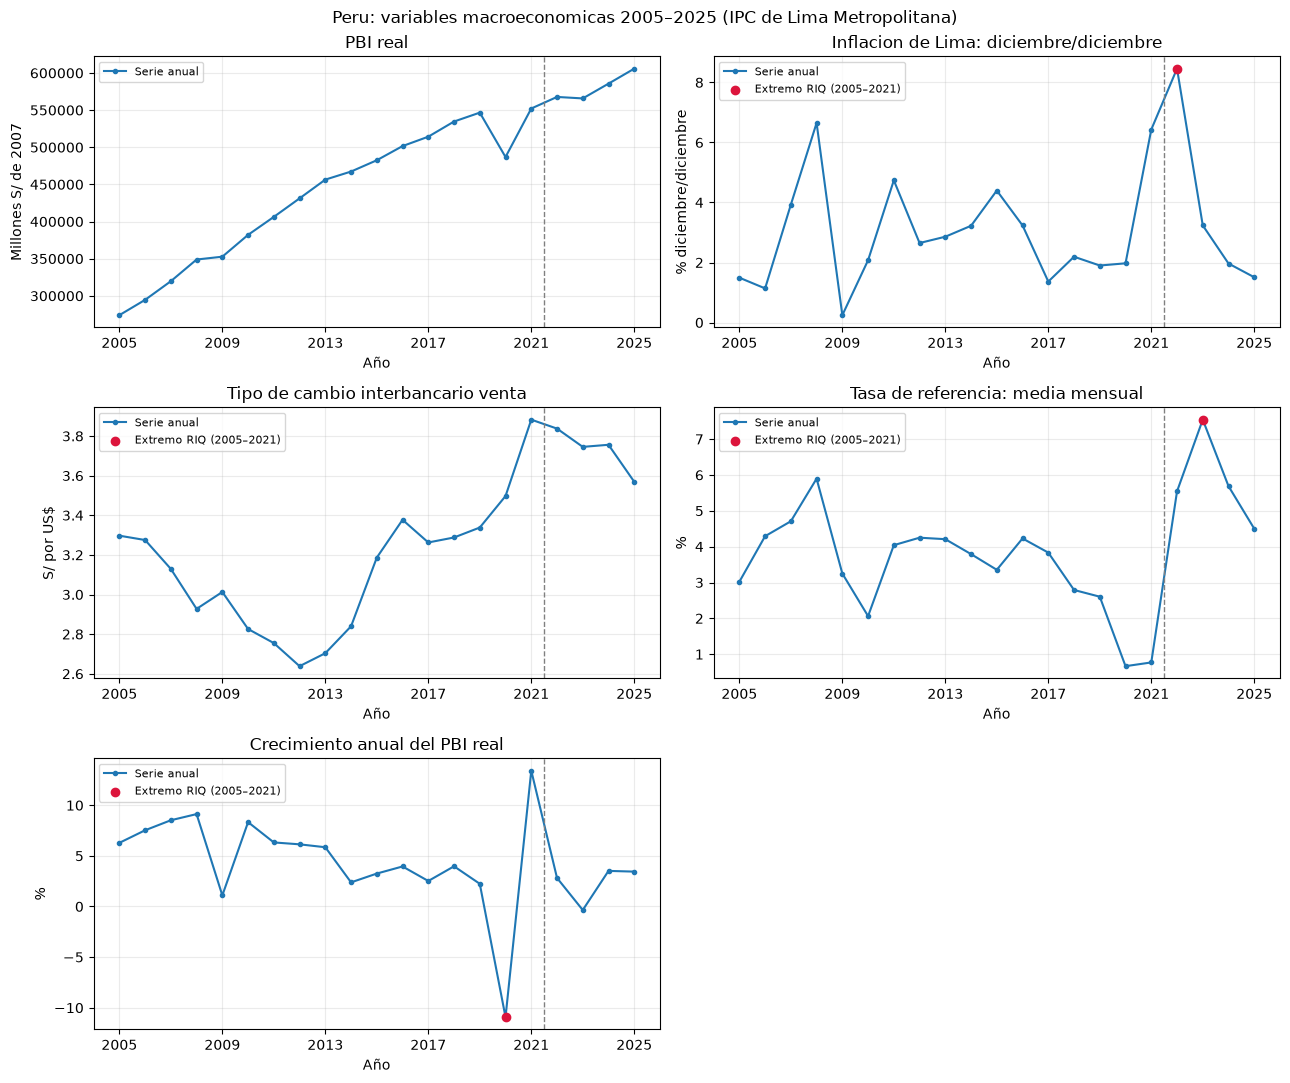

,pbi_real_millones_soles_2007,inflacion_lima_dic_dic_pct,tipo_cambio_promedio_soles_usd,tasa_referencia_promedio_pct,crecimiento_pbi_real_pct
min,273971.1539,0.2453,2.6383,0.6667,-10.9333
max,605788.8640,8.4592,3.8827,7.5417,13.4166


In [8]:
titulos = ["PBI real", "Inflacion de Lima: diciembre/diciembre", "Tipo de cambio interbancario venta",
           "Tasa de referencia: media mensual", "Crecimiento anual del PBI real"]
fig, axes = plt.subplots(3, 2, figsize=(13, 11))
for ax, variable, titulo in zip(axes.flat, anual.columns, titulos):
    unidad = series.set_index("variable").loc[variable, "unidad_final"]
    ax.plot(anual.index, anual[variable], marker="o", markersize=3, label="Serie anual")
    if variable in banderas:
        marca = banderas[variable]
        ax.scatter(anual.index[marca], anual.loc[marca, variable], color="crimson", zorder=3, label="Extremo RIQ (2005–2021)")
    ax.axvline(CORTE_RIQ + 0.5, color="gray", linestyle="--", linewidth=1)
    ax.set(title=titulo, xlabel="Año", ylabel=unidad)
    ax.set_xticks(range(2005, 2026, 4))
    ax.legend(fontsize=8)
axes.flat[-1].set_visible(False)
fig.suptitle("Peru: variables macroeconomicas 2005–2025 (IPC de Lima Metropolitana)")
fig.tight_layout()
plt.show()
display(anual.agg(["min", "max"]).round(4))
etapas.append(8)

La caída del PBI real de 2020 y su recuperación de 2021 se observan en el crecimiento. La inflación alcanza su máximo del periodo en 2022 y la tasa media de referencia en 2023.

**9. Verificación independiente de cálculos**

Se recalculan agregaciones desde los originales y se contrasta el crecimiento con los niveles disponibles desde 2006. También se verifican hashes, abreviaturas y la independencia de los límites respecto de 2022–2025.

In [9]:
for anio in ANIOS:
    for codigo, variable in [("PN01206PM", "tipo_cambio_promedio_soles_usd"), ("PD04722MM", "tasa_referencia_promedio_pct")]:
        valores = tablas[codigo].loc[tablas[codigo].fecha.dt.year.eq(anio), "valor"].to_numpy()
        assert len(valores) == 12
        np.testing.assert_allclose(anual.loc[anio, variable], sum(valores) / 12, rtol=1e-12)
    ipc = tablas["PN38705PM"].set_index("fecha").valor
    esperado = 100 * (ipc.loc[pd.Timestamp(anio, 12, 1)] / ipc.loc[pd.Timestamp(anio - 1, 12, 1)] - 1)
    np.testing.assert_allclose(anual.loc[anio, "inflacion_lima_dic_dic_pct"], esperado, rtol=1e-12)
    original = tablas["PM04860AA"].loc[tablas["PM04860AA"].fecha.dt.year.eq(anio), "valor"].item()
    assert anual.loc[anio, "pbi_real_millones_soles_2007"] == original
for info in manifiesto.values():
    assert hashlib.sha256((ROOT / info["archivo"]).read_bytes()).hexdigest() == info["sha256"]
# La variacion oficial utiliza la misma base real; contraste con los niveles disponibles desde 2006.
crecimiento_original = tablas["PM04863AA"].set_index("fecha").valor.to_numpy()
np.testing.assert_array_equal(anual.crecimiento_pbi_real_pct, crecimiento_original)
np.testing.assert_allclose(anual.loc[2006:, "crecimiento_pbi_real_pct"],
                           anual.pbi_real_millones_soles_2007.pct_change(fill_method=None).loc[2006:] * 100, atol=0.02, rtol=0)
# Perturbar solo años posteriores al corte no debe alterar los limites historicos.
alterado = anual[variables_riq].copy()
alterado.loc[2022:] = alterado.loc[2022:] * 100 + 1000
pd.testing.assert_series_equal(alterado.loc[2005:CORTE_RIQ].quantile(0.25), q1)
pd.testing.assert_series_equal(alterado.loc[2005:CORTE_RIQ].quantile(0.75), q3)
assert not banderas.loc[[2020, 2021], "tasa_referencia_promedio_pct"].any()
assert banderas.loc[2020, "crecimiento_pbi_real_pct"]
for nombre in ["Sep.2020", "Set.2020", "Sept.2020"]:
    assert fecha_bcrp(nombre, "M") == pd.Timestamp(2020, 9, 1)
print("Verificacion correcta: 21 años, 5 variables, formulas, corte RIQ y originales integros.")
etapas.append(9)

Verificacion correcta: 21 años, 5 variables, formulas, corte RIQ y originales integros.


Las agregaciones coinciden con los originales y los límites RIQ permanecen iguales al alterar exclusivamente 2022–2025. Las observaciones extremas se mantienen.

**10. Exportación y trazabilidad**

Se guarda el dataset en data/processed/ y los diccionarios, diagnósticos y validación en reports/. Se conserva precisión float64 y se exige igualdad exacta al releer el CSV con round_trip.

In [10]:
salida = PROCESSED / "macroeconomia_peru_2005_2025.csv"
anual.to_csv(salida, encoding="utf-8", na_rep="")
recuperado = pd.read_csv(salida, index_col="anio", float_precision="round_trip")
pd.testing.assert_frame_equal(anual, recuperado, check_dtype=False, check_exact=True)
series.to_csv(REPORTS / "diccionario_macroeconomia_bcrp.csv", index=False, encoding="utf-8")
calidad.to_csv(REPORTS / "calidad_macroeconomia_bcrp.csv", index=False, encoding="utf-8")
conteos.to_csv(REPORTS / "cobertura_mensual_bcrp.csv", encoding="utf-8")
extremos.to_csv(REPORTS / "extremos_macroeconomia_bcrp.csv", index=False, encoding="utf-8")
banderas.add_prefix("extremo_").to_csv(REPORTS / "banderas_macroeconomia_bcrp.csv", encoding="utf-8")
limites.to_csv(REPORTS / "umbrales_macroeconomia_bcrp.csv", encoding="utf-8", index_label="variable")
hashes_finales = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in protegidos}
assert hashes_finales == hashes_iniciales, "Cambio en archivo preexistente protegido"
assert etapas == list(range(1, 10)), "Ejecutar las celdas en orden desde un kernel limpio"
validacion = {"verificado_utc": datetime.now(timezone.utc).isoformat(), "periodo": [2005, 2025],
    "filas": len(anual), "variables": list(anual.columns), "faltantes": int(anual.isna().sum().sum()),
    "duplicados_anio": int(anual.index.duplicated().sum()), "extremos_conservados": len(extremos),
    "ventana_referencia_riq": [2005, CORTE_RIQ], "variables_riq": variables_riq,
    "verificaciones": ["cobertura original", "12 meses por año", "formulas anuales", "corte RIQ", "hash originales", "relectura CSV exacta"],
    "python": platform.python_version(), "paquetes": versiones,
    "dataset": str(salida.relative_to(ROOT)), "sha256_dataset": hashlib.sha256(salida.read_bytes()).hexdigest(),
    "ejecucion_notebook": {"celdas_codigo": 10, "bloques_previos_completados": etapas.copy(),
        "archivos_preexistentes_preservados": hashes_finales},
    "fuentes": manifiesto}
(REPORTS / "validacion_macroeconomia_bcrp.json").write_text(json.dumps(validacion, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Dataset:", salida.relative_to(ROOT))
print("Dimensiones:", recuperado.shape, "| Faltantes:", validacion["faltantes"])
print("SHA-256:", validacion["sha256_dataset"])
etapas.append(10)

Dataset: data/processed/macroeconomia_peru_2005_2025.csv
Dimensiones: (21, 5) | Faltantes: 0
SHA-256: 7dba8aec32f8eae7086b2cb393f7c22d9741314893bef1f8d081bc8d91b1377e


El CSV conserva 21 años y cinco variables sin faltantes; la relectura reproduce exactamente los valores en memoria. El JSON de validación se genera íntegramente desde este notebook.